# IaCGen vs IaCGOD (MAS) with GLM-5.3-Flash on the real-AWS CloudFormation benchmark

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
plt.style.use('ggplot'); sns.set_palette('muted')
IAC = '..'
ig  = pd.read_csv(f'{IAC}/results/CFN_RealAWS_IaCGen_GLM53F/results_final.csv', low_memory=False)
ms  = pd.read_csv(f'{IAC}/results/CFN_RealAWS_GLM53F/results_final.csv', low_memory=False)
lvl = pd.read_csv(f'{IAC}/data/cfn_eval_benchmark_real_aws.csv')[['row_number','difficulty']]
for d in (ig, ms, lvl): d['row_number'] = d.row_number.astype(int)
def passed(d): return d.final_validation_passed.astype(str).eq('True')
ig['pass'] = passed(ig); ms['pass'] = passed(ms)
m = (lvl.merge(ig[['row_number','run_id','pass','iterations_used','validity']], on='row_number')
        .merge(ms[['row_number','run_id','pass','iterations_used','validity','token_all_tokens','llm_calls_total','duration_seconds']],
               on='row_number', suffixes=('_ig','_ms')))
assert len(m) == 250 and m.row_number.is_unique
print('rows:', len(m), '| IaCGen validity:', ig.validity.value_counts().to_dict(), '| MAS validity:', ms.validity.value_counts().to_dict())

rows: 250 | IaCGen validity: {'valid_pass': 242, 'valid_fail': 7, 'invalid_environment': 1} | MAS validity: {'valid_pass': 228, 'valid_fail': 19, 'invalid_environment': 3}


## 1. Each system on its own criterion (all 250 rows, invalid = not passed)

In [3]:
N = (1, 2, 3, 5, 7, 10, 15)
def summary(p, it):
    ok = p & (it <= 15)
    row = {'passed': int(p.sum()), 'pass %': 100*p.mean(), 'mean iters (all rows)': it.mean(), 'median iters': it.median(),
           'first-try pass %': 100*(p & (it == 1)).mean()}
    row.update({f'passItr@{n} %': 100*(p & (it <= n)).mean() for n in N})
    return row
tab = pd.DataFrame({'IaCGen (deploy only)': summary(m['pass_ig'], m.iterations_used_ig.astype(float)),
                    'MAS (security on)':    summary(m['pass_ms'], m.iterations_used_ms.astype(float))}).T
tab.round(1)

,passed,pass %,mean iters (all rows),median iters,first-try pass %,passItr@1 %,passItr@2 %,passItr@3 %,passItr@5 %,passItr@7 %,passItr@10 %,passItr@15 %
IaCGen (deploy only),242.0,96.8,2.9,2.0,33.2,33.2,66.4,78.4,90.0,93.6,94.8,96.8
MAS (security on),228.0,91.2,4.5,3.0,18.4,18.4,47.2,60.8,78.4,82.8,85.2,91.2


## 2. Paired tests (same 250 scenarios)

In [4]:
a, b = m['pass_ig'], m['pass_ms']
only_ig, only_ms = int((a & ~b).sum()), int((~a & b).sum())
print(f'pass discordant: IaCGen-only {only_ig}, MAS-only {only_ms}, exact McNemar p = {stats.binomtest(only_ig, only_ig+only_ms, 0.5).pvalue:.4f}')
both = a & b
x, y = m.loc[both,'iterations_used_ig'].astype(float), m.loc[both,'iterations_used_ms'].astype(float)
print(f'iterations on rows both pass (n={both.sum()}): IaCGen {x.mean():.2f} vs MAS {y.mean():.2f}, Wilcoxon p = {stats.wilcoxon(x, y).pvalue:.2e}')
x, y = m.iterations_used_ig.astype(float), m.iterations_used_ms.astype(float)
print(f'iterations on all rows: IaCGen {x.mean():.2f} vs MAS {y.mean():.2f}, Wilcoxon p = {stats.wilcoxon(x, y).pvalue:.2e}')

pass discordant: IaCGen-only 18, MAS-only 4, exact McNemar p = 0.0043
iterations on rows both pass (n=224): IaCGen 2.34 vs MAS 3.41, Wilcoxon p = 8.36e-11
iterations on all rows: IaCGen 2.93 vs MAS 4.51, Wilcoxon p = 1.10e-12


## 3. By difficulty level

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_8558/3462977140.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by['MAS_first'] = m.groupby('difficulty').apply(lambda g: 100*((g.iterations_used_ms==1)&g.pass_ms).mean())


,n,IaCGen_pass,MAS_pass,IaCGen_iters,MAS_iters,IaCGen_first,MAS_first
difficulty,,,,,,,
1,50,96.0,84.0,2.6,4.3,44.0,28.0
2,50,100.0,98.0,2.2,3.0,42.0,34.0
3,50,96.0,92.0,3.0,4.4,26.0,10.0
4,50,92.0,90.0,3.7,5.3,36.0,12.0
5,50,100.0,92.0,3.2,5.5,18.0,8.0


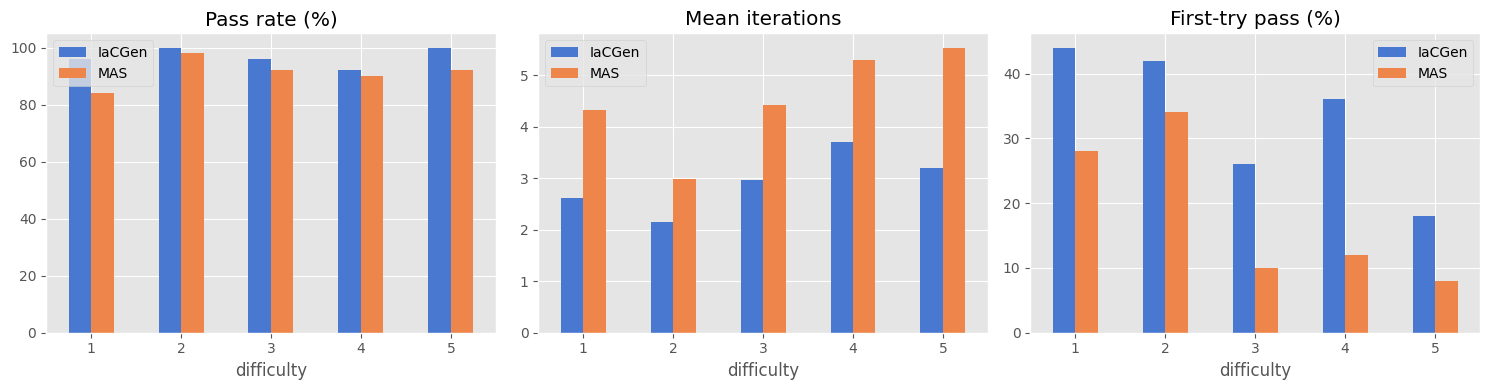

In [5]:
by = m.groupby('difficulty').agg(n=('row_number','size'),
        IaCGen_pass=('pass_ig', lambda s: 100*s.mean()), MAS_pass=('pass_ms', lambda s: 100*s.mean()),
        IaCGen_iters=('iterations_used_ig','mean'), MAS_iters=('iterations_used_ms','mean'),
        IaCGen_first=('iterations_used_ig', lambda s: 100*(s==1).mean()))
by['MAS_first'] = m.groupby('difficulty').apply(lambda g: 100*((g.iterations_used_ms==1)&g.pass_ms).mean())
display(by.round(1))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k, (c1, c2, t) in enumerate([('IaCGen_pass','MAS_pass','Pass rate (%)'), ('IaCGen_iters','MAS_iters','Mean iterations'), ('IaCGen_first','MAS_first','First-try pass (%)')]):
    by[[c1, c2]].rename(columns=lambda s: s.split('_')[0]).plot.bar(ax=ax[k], rot=0); ax[k].set_title(t); ax[k].set_xlabel('difficulty')
plt.tight_layout(); plt.savefig('plots/iacgen_vs_mas_glm_by_level.png', dpi=150); plt.show()

## 4. Pass rate within n iterations

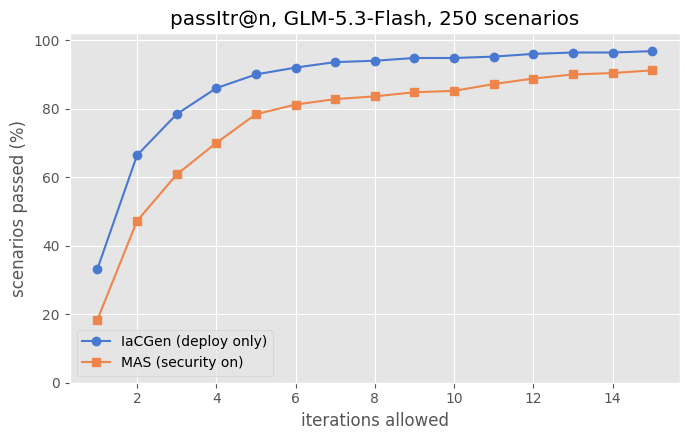

In [6]:
ns = list(range(1, 16))
curve = lambda p, it: [100*(p & (it <= n)).mean() for n in ns]
plt.figure(figsize=(7, 4.5))
plt.plot(ns, curve(m['pass_ig'], m.iterations_used_ig.astype(float)), 'o-', label='IaCGen (deploy only)')
plt.plot(ns, curve(m['pass_ms'], m.iterations_used_ms.astype(float)), 's-', label='MAS (security on)')
plt.xlabel('iterations allowed'); plt.ylabel('scenarios passed (%)'); plt.ylim(0, 102); plt.legend(); plt.title('passItr@n, GLM-5.3-Flash, 250 scenarios')
plt.tight_layout(); plt.savefig('plots/iacgen_vs_mas_glm_passitr.png', dpi=150); plt.show()

## 5. Joint criterion: deploys AND no critical/high Trivy finding

In [7]:
def trivy(path, runs):
    t = pd.read_csv(path, low_memory=False)
    t = t.drop_duplicates('run_id', keep='last').set_index('run_id')
    clean = (t.severity_critical_failed.fillna(0) == 0) & (t.severity_high_failed.fillna(0) == 0) & t.error.isna()
    return runs.map(clean).fillna(False)
m['clean_ig'] = trivy('result/final/Trivy_CFN_RealAWS_IaCGen_GLM53F.csv', m.run_id_ig)
m['clean_ms'] = trivy('result/final/Trivy_CFN_RealAWS_GLM53F.csv', m.run_id_ms)
m['joint_ig'] = m.pass_ig & m.clean_ig; m['joint_ms'] = m.pass_ms & m.clean_ms
j = pd.DataFrame({'deploy pass %': [100*m.pass_ig.mean(), 100*m.pass_ms.mean()],
                  'of deploy-passing: Trivy clean %': [100*m.clean_ig[m.pass_ig].mean(), 100*m.clean_ms[m.pass_ms].mean()],
                  'JOINT pass % (deploy + no critical/high)': [100*m.joint_ig.mean(), 100*m.joint_ms.mean()]},
                 index=['IaCGen', 'MAS']).round(1)
display(j)
a, b = m.joint_ig, m.joint_ms
o1, o2 = int((a & ~b).sum()), int((~a & b).sum())
print(f'joint criterion: IaCGen-only {o1}, MAS-only {o2}, exact McNemar p = {stats.binomtest(o1, o1+o2, 0.5).pvalue:.2e}')

,deploy pass %,of deploy-passing: Trivy clean %,JOINT pass % (deploy + no critical/high)
IaCGen,96.8,77.7,75.2
MAS,91.2,98.7,90.0


joint criterion: IaCGen-only 15, MAS-only 52, exact McNemar p = 6.46e-06


## 6. Failures

In [8]:
print('IaCGen failures by stage:'); display(ig[~ig['pass']].groupby(['failed_at_stage','validity']).size().to_frame('rows'))
print('IaCGen failing rows:', sorted(ig[~ig['pass']].row_number)); print('MAS failing rows:', sorted(ms[~ms['pass']].row_number))
print('failed by both:', sorted(set(ig[~ig['pass']].row_number) & set(ms[~ms['pass']].row_number)))
print('failed by IaCGen only:', sorted(set(ig[~ig['pass']].row_number) - set(ms[~ms['pass']].row_number)))

IaCGen failures by stage:


rows
failed_at_stage   validity                 
deployment        invalid_environment     1
                  valid_fail              6
syntax_validation valid_fail              1

IaCGen failing rows: [6, 13, 79, 91, 114, 123, 150, 152]
MAS failing rows: [1, 2, 3, 6, 17, 20, 22, 26, 74, 79, 102, 103, 123, 137, 138, 150, 155, 174, 175, 177, 180, 263]
failed by both: [6, 79, 123, 150]
failed by IaCGen only: [13, 91, 114, 152]


## 7. Resource coverage and accuracy of the final templates

In [9]:
cov_ig = pd.read_csv('result/final/Coverage_CFN_RealAWS_IaCGen_GLM53F.csv'); cov_ms = pd.read_csv('result/final/Coverage_CFN_RealAWS_GLM53F.csv')
cv = cov_ig[['row_number','coverage_pct','accuracy_pct']].merge(cov_ms[['row_number','coverage_pct','accuracy_pct']], on='row_number', suffixes=('_ig','_ms'))
cv = cv.merge(m[['row_number','pass_ig','pass_ms']], on='row_number')
both = cv[cv.pass_ig & cv.pass_ms]
print(f'rows where both pass (n={len(both)}): coverage IaCGen {both.coverage_pct_ig.mean():.1f}% vs MAS {both.coverage_pct_ms.mean():.1f}%; accuracy {both.accuracy_pct_ig.mean():.1f}% vs {both.accuracy_pct_ms.mean():.1f}%')
print(f'wilcoxon coverage p = {stats.wilcoxon(both.coverage_pct_ig, both.coverage_pct_ms).pvalue:.3f}, accuracy p = {stats.wilcoxon(both.accuracy_pct_ig, both.accuracy_pct_ms).pvalue:.3f}')

rows where both pass (n=224): coverage IaCGen 87.9% vs MAS 87.6%; accuracy 84.5% vs 82.5%
wilcoxon coverage p = 0.204, accuracy p = 0.061


## 8. Cost (MAS only; IaCGen records no token accounting)

In [10]:
print(f'MAS GLM: {m.token_all_tokens.mean()/1e3:.0f}k tokens/scenario, {m.llm_calls_total.mean():.1f} LLM calls/scenario, {m.duration_seconds.mean()/60:.1f} min/scenario')

MAS GLM: 195k tokens/scenario, 12.2 LLM calls/scenario, 23.9 min/scenario
